In [103]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/ishaans23/final-classifier-artifact/head_training_history.csv
/kaggle/input/datasets/ishaans23/final-classifier-artifact/layer4_training_history.csv
/kaggle/input/datasets/ishaans23/final-classifier-artifact/model_metadata.json
/kaggle/input/datasets/ishaans23/final-classifier-artifact/resnet50_layer4_best.pth
/kaggle/input/datasets/ishaans23/final-classifier-artifact/training_summary.json
/kaggle/input/datasets/ishaans23/cbis-ddsm-training/cache_info.json
/kaggle/input/datasets/ishaans23/cbis-ddsm-training/excluded_mass_cases.csv
/kaggle/input/datasets/ishaans23/cbis-ddsm-training/image_metadata.csv
/kaggle/input/datasets/ishaans23/cbis-ddsm-training/shared_mass_calc_audit.csv
/kaggle/input/datasets/ishaans23/cbis-ddsm-training/masks/P_00001_LEFT_CC.png
/kaggle/input/datasets/ishaans23/cbis-ddsm-training/masks/P_00001_LEFT_MLO.png
/kaggle/input/datasets/ishaans23/cbis-ddsm-training/masks/P_00004_LEFT_CC.png
/kaggle/input/datasets/ishaans23/cbis-ddsm-training/mas

In [104]:
from pathlib import Path
import random

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

In [105]:
SEED = 42

TARGET_HEIGHT = 1024
TARGET_WIDTH = 640

OVERFIT_SAMPLES = 1
BATCH_SIZE = 1

OVERFIT_EPOCHS = 300
OVERFIT_TARGET_DICE = 0.95

LEARNING_RATE = 1e-3
WEIGHT_DECAY = 0.0

USE_AMP = False

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

OUTPUT_DIR = Path(
    "/kaggle/working/segmentation_experiment"
)

CHECKPOINT_DIR = (
    OUTPUT_DIR / "checkpoints"
)

FIGURE_DIR = (
    OUTPUT_DIR / "figures"
)

CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

OVERFIT_CHECKPOINT = (
    CHECKPOINT_DIR
    / "unet_single_image_overfit_best.pth"
)

print("Output:", OUTPUT_DIR)
print("AMP enabled:", USE_AMP)

Output: /kaggle/working/segmentation_experiment
AMP enabled: False


In [106]:
KAGGLE_INPUT_ROOT = Path(
    "/kaggle/input"
)

dataset_candidates = []

for cache_info_path in KAGGLE_INPUT_ROOT.rglob(
    "cache_info.json"
):
    candidate_root = (
        cache_info_path.parent
    )

    required = [
        candidate_root / "npy",
        candidate_root / "masks",
        candidate_root / "splits",
    ]

    if all(
        path.exists()
        for path in required
    ):
        dataset_candidates.append(
            candidate_root
        )

assert len(dataset_candidates) > 0, (
    "Could not locate the model-ready "
    "CBIS-DDSM dataset."
)

dataset_candidates = sorted(
    dataset_candidates,
    key=lambda path: len(str(path)),
)

PROJECT_ROOT = dataset_candidates[0]

print("Dataset:")
print(PROJECT_ROOT)

Dataset:
/kaggle/input/datasets/ishaans23/cbis-ddsm-training


In [107]:
train_df = pd.read_csv(
    PROJECT_ROOT
    / "splits"
    / "train.csv"
)

print("Training samples:", len(train_df))

print(
    "\nAbnormality distribution:"
)

print(
    train_df[
        "abnormality_type"
    ].value_counts()
)

Training samples: 1885

Abnormality distribution:
abnormality_type
calcification         1027
mass                   821
mass+calcification      37
Name: count, dtype: int64


In [108]:
# ============================================================
# STRICT 1-IMAGE OVERFIT TEST
# Use one large mass lesion
# ============================================================

overfit_df = (
    train_df[
        train_df["abnormality_type"]
        .str.lower()
        .eq("mass")
    ]
    .sort_values(
        "mask_pixels",
        ascending=False,
    )
    .head(1)
    .reset_index(drop=True)
)

display(
    overfit_df[
        [
            "image_key",
            "patient_id",
            "abnormality_type",
            "pathology",
            "mask_pixels",
        ]
    ]
)

assert len(overfit_df) == 1

,image_key,patient_id,abnormality_type,pathology,mask_pixels
0,P_00695_RIGHT_MLO,P_00695,mass,MALIGNANT,1256421


In [109]:
class CBISSegmentationDataset(Dataset):

    def __init__(
        self,
        dataframe,
        root_dir,
    ):
        self.dataframe = (
            dataframe
            .reset_index(drop=True)
        )

        self.root_dir = Path(
            root_dir
        )

    def __len__(self):

        return len(
            self.dataframe
        )

    def __getitem__(
        self,
        idx,
    ):

        row = (
            self.dataframe
            .iloc[idx]
        )

        image_path = (
            self.root_dir
            / row["npy_path"]
        )

        mask_path = (
            self.root_dir
            / row["mask_path"]
        )


        image = np.load(
            image_path
        )

        mask = cv2.imread(
            str(mask_path),
            cv2.IMREAD_GRAYSCALE,
        )


        if image.shape != (
            TARGET_HEIGHT,
            TARGET_WIDTH,
        ):
            raise ValueError(
                f"{row['image_key']}: "
                f"unexpected image shape "
                f"{image.shape}"
            )

        if mask.shape != (
            TARGET_HEIGHT,
            TARGET_WIDTH,
        ):
            raise ValueError(
                f"{row['image_key']}: "
                f"unexpected mask shape "
                f"{mask.shape}"
            )


        image = (
            image.astype(
                np.float32
            )
            / 65535.0
        )

        mask = (
            mask > 0
        ).astype(
            np.float32
        )


        image = (
            torch
            .from_numpy(image)
            .unsqueeze(0)
        )

        mask = (
            torch
            .from_numpy(mask)
            .unsqueeze(0)
        )


        return (
            image,
            mask,
            row["image_key"],
        )

In [110]:
overfit_dataset = (
    CBISSegmentationDataset(
        dataframe=overfit_df,
        root_dir=PROJECT_ROOT,
    )
)


overfit_loader = DataLoader(
    overfit_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
)


print(
    "Samples:",
    len(overfit_dataset)
)

print(
    "Batches:",
    len(overfit_loader)
)

Samples: 1
Batches: 1


In [111]:
# ============================================================
# MEASURE FOREGROUND / BACKGROUND IMBALANCE
# ============================================================

foreground_pixels = 0
background_pixels = 0

for _, masks, _ in overfit_loader:

    foreground_pixels += int(
        masks.sum().item()
    )

    background_pixels += int(
        masks.numel()
        - masks.sum().item()
    )

raw_pos_weight = (
    background_pixels
    / foreground_pixels
)

# Cap the weight to avoid excessively large gradients.
POS_WEIGHT = min(
    raw_pos_weight,
    50.0,
)

print(
    "Foreground pixels:",
    foreground_pixels,
)

print(
    "Background pixels:",
    background_pixels,
)

print(
    "Raw positive weight:",
    raw_pos_weight,
)

print(
    "Using positive weight:",
    POS_WEIGHT,
)

Foreground pixels: 160920
Background pixels: 494440
Raw positive weight: 3.072582649763858
Using positive weight: 3.072582649763858


In [112]:
images, masks, image_keys = next(
    iter(overfit_loader)
)


print(
    "Images:",
    images.shape
)

print(
    "Masks:",
    masks.shape
)

print(
    "Image dtype:",
    images.dtype
)

print(
    "Mask dtype:",
    masks.dtype
)

print(
    "Image range:",
    float(images.min()),
    "to",
    float(images.max()),
)

print(
    "Mask values:",
    torch.unique(masks)
)

print(
    "Example keys:",
    image_keys
)

Images: torch.Size([1, 1, 1024, 640])
Masks: torch.Size([1, 1, 1024, 640])
Image dtype: torch.float32
Mask dtype: torch.float32
Image range: 0.0 to 0.7823758125305176
Mask values: tensor([0., 1.])
Example keys: ('P_00695_RIGHT_MLO',)


In [113]:
class DoubleConv(nn.Module):

    def __init__(
        self,
        in_channels,
        out_channels,
    ):
        super().__init__()

        self.block = nn.Sequential(

            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=True,
            ),

            nn.ReLU(
                inplace=True
            ),

            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=True,
            ),

            nn.ReLU(
                inplace=True
            ),
        )

    def forward(
        self,
        x,
    ):

        return self.block(x)

In [114]:
class UpBlock(nn.Module):

    def __init__(
        self,
        in_channels,
        skip_channels,
        out_channels,
    ):
        super().__init__()

        self.up = nn.ConvTranspose2d(
            in_channels,
            out_channels,
            kernel_size=2,
            stride=2,
        )

        self.conv = DoubleConv(
            out_channels
            + skip_channels,
            out_channels,
        )

    def forward(
        self,
        x,
        skip,
    ):

        x = self.up(x)


        if x.shape[-2:] != (
            skip.shape[-2:]
        ):

            x = F.interpolate(
                x,
                size=skip.shape[-2:],
                mode="bilinear",
                align_corners=False,
            )


        x = torch.cat(
            [
                skip,
                x,
            ],
            dim=1,
        )

        return self.conv(x)

In [115]:
class UNet(nn.Module):

    def __init__(
        self,
        in_channels=1,
        out_channels=1,
        base_channels=16,
    ):
        super().__init__()


        # Encoder
        self.enc1 = DoubleConv(
            in_channels,
            base_channels,
        )

        self.enc2 = DoubleConv(
            base_channels,
            base_channels * 2,
        )

        self.enc3 = DoubleConv(
            base_channels * 2,
            base_channels * 4,
        )

        self.enc4 = DoubleConv(
            base_channels * 4,
            base_channels * 8,
        )


        self.pool = nn.MaxPool2d(
            kernel_size=2,
            stride=2,
        )


        # Bottleneck
        self.bottleneck = DoubleConv(
            base_channels * 8,
            base_channels * 16,
        )


        # Decoder
        self.up4 = UpBlock(
            base_channels * 16,
            base_channels * 8,
            base_channels * 8,
        )

        self.up3 = UpBlock(
            base_channels * 8,
            base_channels * 4,
            base_channels * 4,
        )

        self.up2 = UpBlock(
            base_channels * 4,
            base_channels * 2,
            base_channels * 2,
        )

        self.up1 = UpBlock(
            base_channels * 2,
            base_channels,
            base_channels,
        )


        self.output = nn.Conv2d(
            base_channels,
            out_channels,
            kernel_size=1,
        )


    def forward(
        self,
        x,
    ):

        e1 = self.enc1(x)

        e2 = self.enc2(
            self.pool(e1)
        )

        e3 = self.enc3(
            self.pool(e2)
        )

        e4 = self.enc4(
            self.pool(e3)
        )


        bottleneck = (
            self.bottleneck(
                self.pool(e4)
            )
        )


        d4 = self.up4(
            bottleneck,
            e4,
        )

        d3 = self.up3(
            d4,
            e3,
        )

        d2 = self.up2(
            d3,
            e2,
        )

        d1 = self.up1(
            d2,
            e1,
        )


        return self.output(
            d1
        )

In [116]:
device = torch.device(
    "cuda:0"
    if torch.cuda.is_available()
    else "cpu"
)

model = UNet(
    in_channels=1,
    out_channels=1,
    base_channels=32,
)

model = model.to(
    device
)

print("Device:", device)

if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

trainable_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print(
    "Trainable parameters:",
    f"{trainable_parameters:,}"
)

Device: cuda:0
GPU: Tesla T4
Trainable parameters: 7,759,521


In [117]:
images, masks, _ = next(
    iter(overfit_loader)
)

images = images.to(
    device
)


with torch.inference_mode():

    logits = model(
        images
    )


print(
    "Input:",
    images.shape
)

print(
    "Output:",
    logits.shape
)

print(
    "Target:",
    masks.shape
)


assert logits.shape == masks.shape

print(
    "\nU-Net output shape verified."
)

Input: torch.Size([1, 1, 1024, 640])
Output: torch.Size([1, 1, 1024, 640])
Target: torch.Size([1, 1, 1024, 640])

U-Net output shape verified.


In [118]:
# ============================================================
# WEIGHTED BCE + DICE LOSS
# ============================================================

pos_weight_tensor = torch.tensor(
    [POS_WEIGHT],
    dtype=torch.float32,
    device=device,
)

bce_loss = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight_tensor
)


def soft_dice_score(
    logits,
    targets,
    smooth=1.0,
):

    probabilities = torch.sigmoid(
        logits
    )

    dimensions = (
        1,
        2,
        3,
    )

    intersection = (
        probabilities
        * targets
    ).sum(
        dim=dimensions
    )

    denominator = (
        probabilities.sum(
            dim=dimensions
        )
        +
        targets.sum(
            dim=dimensions
        )
    )

    dice = (
        2.0 * intersection
        + smooth
    ) / (
        denominator
        + smooth
    )

    return dice.mean()


def dice_loss(
    logits,
    targets,
):

    return (
        1.0
        - soft_dice_score(
            logits,
            targets,
        )
    )


def segmentation_loss(
    logits,
    targets,
):

    bce = bce_loss(
        logits,
        targets,
    )

    dice = dice_loss(
        logits,
        targets,
    )

    # Strongly prioritize spatial overlap
    total = (
        0.1 * bce
        +
        0.9 * dice
    )

    return (
        total,
        bce,
        dice,
    )

In [119]:
def segmentation_metrics(
    logits,
    targets,
    threshold=0.5,
    smooth=1.0,
):

    probabilities = (
        torch.sigmoid(logits)
    )

    predictions = (
        probabilities
        >= threshold
    ).float()


    dimensions = (
        1,
        2,
        3,
    )


    intersection = (
        predictions
        * targets
    ).sum(
        dim=dimensions
    )


    pred_pixels = (
        predictions.sum(
            dim=dimensions
        )
    )

    target_pixels = (
        targets.sum(
            dim=dimensions
        )
    )


    dice = (
        2 * intersection
        + smooth
    ) / (
        pred_pixels
        + target_pixels
        + smooth
    )


    union = (
        pred_pixels
        + target_pixels
        - intersection
    )


    iou = (
        intersection
        + smooth
    ) / (
        union
        + smooth
    )


    return (
        dice.mean().item(),
        iou.mean().item(),
    )

In [120]:
# ============================================================
# OPTIMIZER FOR STRICT OVERFIT TEST
# ============================================================

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=USE_AMP,
)

print(
    "Learning rate:",
    LEARNING_RATE
)

print(
    "Weight decay:",
    WEIGHT_DECAY
)

print(
    "AMP enabled:",
    USE_AMP
)

Learning rate: 0.001
Weight decay: 0.0
AMP enabled: False


In [121]:
overfit_history = []

best_dice = -float("inf")


for epoch in range(
    1,
    OVERFIT_EPOCHS + 1,
):

    model.train()

    running_loss = 0.0
    running_bce = 0.0
    running_dice_loss = 0.0

    epoch_dice = []
    epoch_iou = []


    for (
        images,
        masks,
        _,
    ) in overfit_loader:

        images = images.to(
            device,
            non_blocking=True,
        )

        masks = masks.to(
            device,
            non_blocking=True,
        )


        optimizer.zero_grad(
            set_to_none=True
        )


        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=USE_AMP,
        ):

            logits = model(
                images
            )

            (
                loss,
                bce,
                dice_component,
            ) = segmentation_loss(
                logits,
                masks,
            )


        scaler.scale(
            loss
        ).backward()

        scaler.step(
            optimizer
        )

        scaler.update()


        dice_value, iou_value = (
            segmentation_metrics(
                logits.detach(),
                masks,
            )
        )


        running_loss += (
            loss.item()
        )

        running_bce += (
            bce.item()
        )

        running_dice_loss += (
            dice_component.item()
        )

        epoch_dice.append(
            dice_value
        )

        epoch_iou.append(
            iou_value
        )


    average_loss = (
        running_loss
        / len(overfit_loader)
    )

    average_bce = (
        running_bce
        / len(overfit_loader)
    )

    average_dice_loss = (
        running_dice_loss
        / len(overfit_loader)
    )

    average_dice = float(
        np.mean(epoch_dice)
    )

    average_iou = float(
        np.mean(epoch_iou)
    )


    overfit_history.append(
        {
            "epoch": epoch,
            "loss": average_loss,
            "bce": average_bce,
            "dice_loss": average_dice_loss,
            "dice": average_dice,
            "iou": average_iou,
        }
    )


    if average_dice > best_dice:

        best_dice = (
            average_dice
        )

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": (
                    model.state_dict()
                ),
                "optimizer_state_dict": (
                    optimizer.state_dict()
                ),
                "dice": average_dice,
                "iou": average_iou,
                "loss": average_loss,
            },
            OVERFIT_CHECKPOINT,
        )


    if (
        epoch == 1
        or epoch % 5 == 0
        or average_dice
        >= OVERFIT_TARGET_DICE
    ):

        print(
            f"Epoch {epoch:03d} | "
            f"Loss {average_loss:.4f} | "
            f"Dice {average_dice:.4f} | "
            f"IoU {average_iou:.4f}"
        )


    if (
        average_dice
        >= OVERFIT_TARGET_DICE
    ):

        print(
            "\nOverfit target reached."
        )

        break

Epoch 001 | Loss 0.7088 | Dice 0.0000 | IoU 0.0000
Epoch 005 | Loss 0.6980 | Dice 0.3951 | IoU 0.2462
Epoch 010 | Loss 0.6236 | Dice 0.5724 | IoU 0.4010
Epoch 015 | Loss 0.4794 | Dice 0.8378 | IoU 0.7209
Epoch 020 | Loss 0.3049 | Dice 0.8967 | IoU 0.8128
Epoch 025 | Loss 0.2151 | Dice 0.8596 | IoU 0.7538
Epoch 030 | Loss 0.1445 | Dice 0.8892 | IoU 0.8006
Epoch 035 | Loss 0.0802 | Dice 0.9415 | IoU 0.8894
Epoch 038 | Loss 0.0636 | Dice 0.9526 | IoU 0.9095

Overfit target reached.


In [122]:
overfit_history_df = pd.DataFrame(
    overfit_history
)


overfit_history_df.to_csv(
    OUTPUT_DIR
    / "overfit_history.csv",
    index=False,
)


display(
    overfit_history_df.tail(10)
)


print(
    "\nBest Dice:",
    best_dice
)

print(
    "Checkpoint:",
    OVERFIT_CHECKPOINT
)

,epoch,loss,bce,dice_loss,dice,iou
28,29,0.150883,0.360730,0.127567,0.883084,0.790646
29,30,0.144550,0.384032,0.117941,0.889232,0.800557
30,31,0.123821,0.340321,0.099765,0.910399,0.835535
31,32,0.087938,0.204340,0.075005,0.936426,0.880453
32,33,0.099479,0.263571,0.081246,0.924706,0.859957
33,34,0.087202,0.255475,0.068505,0.938382,0.883917
34,35,0.080235,0.231745,0.063401,0.941472,0.889417
35,36,0.076572,0.219149,0.060730,0.941936,0.890246
36,37,0.069854,0.208327,0.054468,0.947663,0.900532
37,38,0.063616,0.188973,0.049688,0.952583,0.909460



Best Dice: 0.952583372592926
Checkpoint: /kaggle/working/segmentation_experiment/checkpoints/unet_single_image_overfit_best.pth


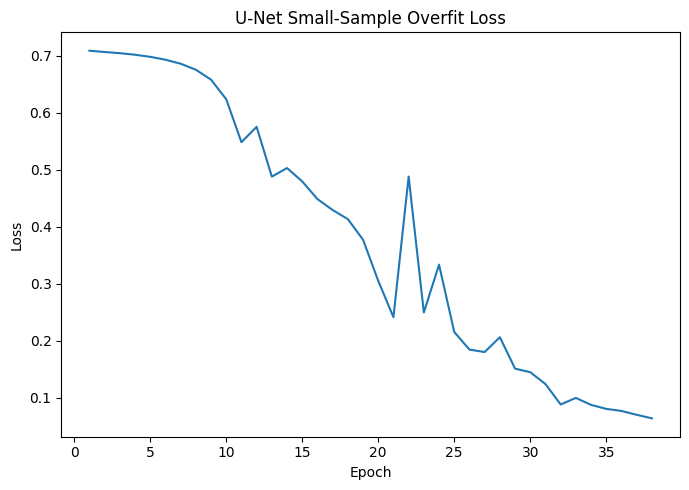

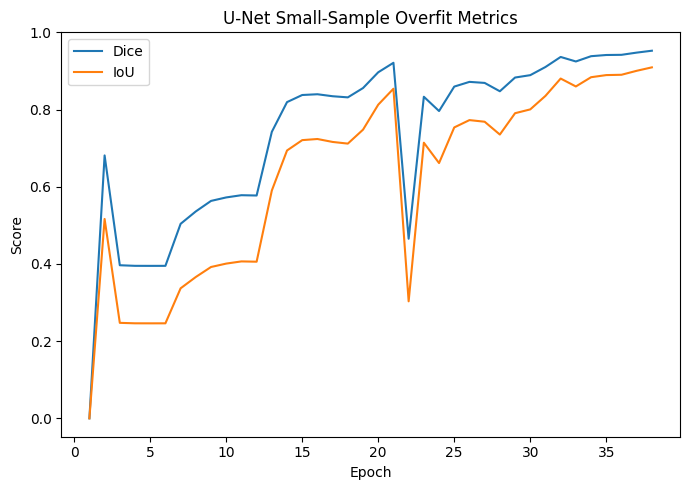

In [123]:
plt.figure(
    figsize=(7, 5)
)

plt.plot(
    overfit_history_df[
        "epoch"
    ],
    overfit_history_df[
        "loss"
    ],
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Loss"
)

plt.title(
    "U-Net Small-Sample Overfit Loss"
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "overfit_loss.png",
    dpi=180,
)

plt.show()


plt.figure(
    figsize=(7, 5)
)

plt.plot(
    overfit_history_df[
        "epoch"
    ],
    overfit_history_df[
        "dice"
    ],
    label="Dice",
)

plt.plot(
    overfit_history_df[
        "epoch"
    ],
    overfit_history_df[
        "iou"
    ],
    label="IoU",
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Score"
)

plt.title(
    "U-Net Small-Sample Overfit Metrics"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "overfit_metrics.png",
    dpi=180,
)

plt.show()

In [124]:
checkpoint = torch.load(
    OVERFIT_CHECKPOINT,
    map_location=device,
    weights_only=False,
)


model.load_state_dict(
    checkpoint[
        "model_state_dict"
    ]
)

model.eval()


print(
    "Best epoch:",
    checkpoint["epoch"]
)

print(
    "Best Dice:",
    checkpoint["dice"]
)

print(
    "Best IoU:",
    checkpoint["iou"]
)

Best epoch: 38
Best Dice: 0.952583372592926
Best IoU: 0.9094600677490234


,threshold,dice,iou
0,0.10,0.947398,0.900055
1,0.15,0.948435,0.901928
2,0.20,0.949121,0.903170
3,0.25,0.949435,0.903738
4,0.30,0.949673,0.904170
5,0.35,0.949692,0.904203
6,0.40,0.949587,0.904013
7,0.45,0.949434,0.903736
8,0.50,0.949047,0.903036
9,0.55,0.948656,0.902327



Best threshold: 0.3500000000000001
Best average Dice: 0.9496915936470032
Best average IoU: 0.904202938079834


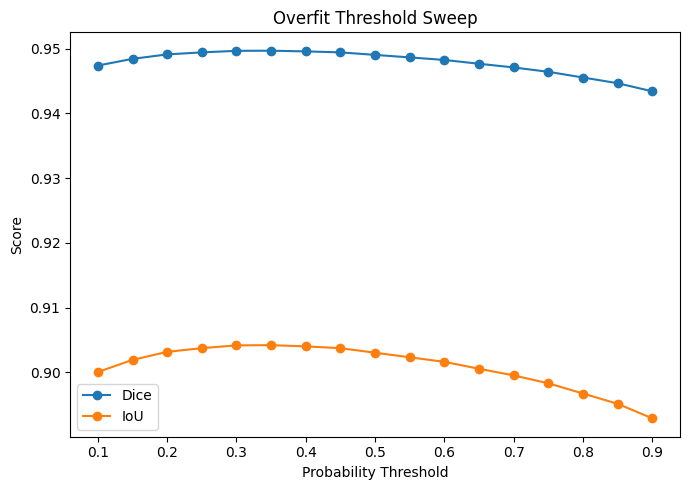

In [125]:
# ============================================================
# THRESHOLD SWEEP ON OVERFIT SET
# ============================================================

thresholds = np.arange(
    0.10,
    0.91,
    0.05,
)

threshold_results = []


model.eval()

with torch.inference_mode():

    for threshold in thresholds:

        sample_dice = []
        sample_iou = []

        for (
            images,
            masks,
            _,
        ) in overfit_loader:

            images = images.to(
                device
            )

            masks = masks.to(
                device
            )

            logits = model(
                images
            )

            probabilities = torch.sigmoid(
                logits
            )

            predictions = (
                probabilities
                >= threshold
            ).float()


            dimensions = (
                1,
                2,
                3,
            )

            intersection = (
                predictions
                * masks
            ).sum(
                dim=dimensions
            )

            pred_pixels = (
                predictions.sum(
                    dim=dimensions
                )
            )

            target_pixels = (
                masks.sum(
                    dim=dimensions
                )
            )

            dice = (
                2 * intersection
                + 1.0
            ) / (
                pred_pixels
                + target_pixels
                + 1.0
            )

            union = (
                pred_pixels
                + target_pixels
                - intersection
            )

            iou = (
                intersection
                + 1.0
            ) / (
                union
                + 1.0
            )


            sample_dice.extend(
                dice.cpu().numpy()
            )

            sample_iou.extend(
                iou.cpu().numpy()
            )


        threshold_results.append(
            {
                "threshold": threshold,
                "dice": np.mean(
                    sample_dice
                ),
                "iou": np.mean(
                    sample_iou
                ),
            }
        )


threshold_df = pd.DataFrame(
    threshold_results
)


best_row = threshold_df.loc[
    threshold_df[
        "dice"
    ].idxmax()
]


display(
    threshold_df
)

print(
    "\nBest threshold:",
    best_row["threshold"]
)

print(
    "Best average Dice:",
    best_row["dice"]
)

print(
    "Best average IoU:",
    best_row["iou"]
)


plt.figure(
    figsize=(7, 5)
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["dice"],
    marker="o",
    label="Dice",
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["iou"],
    marker="o",
    label="IoU",
)

plt.xlabel(
    "Probability Threshold"
)

plt.ylabel(
    "Score"
)

plt.title(
    "Overfit Threshold Sweep"
)

plt.legend()

plt.tight_layout()

plt.show()

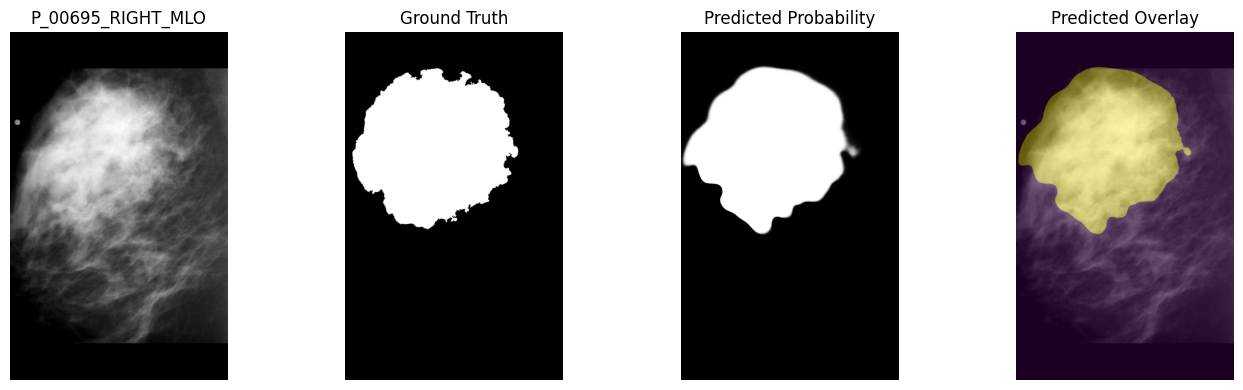

In [126]:
def visualize_predictions(
    model,
    dataset,
    device,
    max_samples=8,
):

    model.eval()

    num_samples = min(
        max_samples,
        len(dataset),
    )


    fig, axes = plt.subplots(
        num_samples,
        4,
        figsize=(
            14,
            4 * num_samples,
        ),
    )


    if num_samples == 1:
        axes = axes[
            np.newaxis,
            :
        ]


    with torch.inference_mode():

        for i in range(
            num_samples
        ):

            (
                image,
                mask,
                image_key,
            ) = dataset[i]


            logits = model(
                image
                .unsqueeze(0)
                .to(device)
            )


            probability = (
                torch.sigmoid(
                    logits
                )
                .squeeze()
                .cpu()
                .numpy()
            )


            prediction = (
                probability
                >= 0.5
            )


            image_np = (
                image
                .squeeze()
                .numpy()
            )

            mask_np = (
                mask
                .squeeze()
                .numpy()
            )


            axes[i, 0].imshow(
                image_np,
                cmap="gray",
            )

            axes[i, 0].set_title(
                image_key
            )


            axes[i, 1].imshow(
                mask_np,
                cmap="gray",
            )

            axes[i, 1].set_title(
                "Ground Truth"
            )


            axes[i, 2].imshow(
                probability,
                cmap="gray",
                vmin=0,
                vmax=1,
            )

            axes[i, 2].set_title(
                "Predicted Probability"
            )


            axes[i, 3].imshow(
                image_np,
                cmap="gray",
            )

            axes[i, 3].imshow(
                prediction,
                alpha=0.4,
            )

            axes[i, 3].set_title(
                "Predicted Overlay"
            )


            for ax in axes[i]:

                ax.axis("off")


    plt.tight_layout()

    plt.savefig(
        FIGURE_DIR
        / "overfit_predictions.png",
        dpi=180,
        bbox_inches="tight",
    )

    plt.show()


visualize_predictions(
    model=model,
    dataset=overfit_dataset,
    device=device,
)

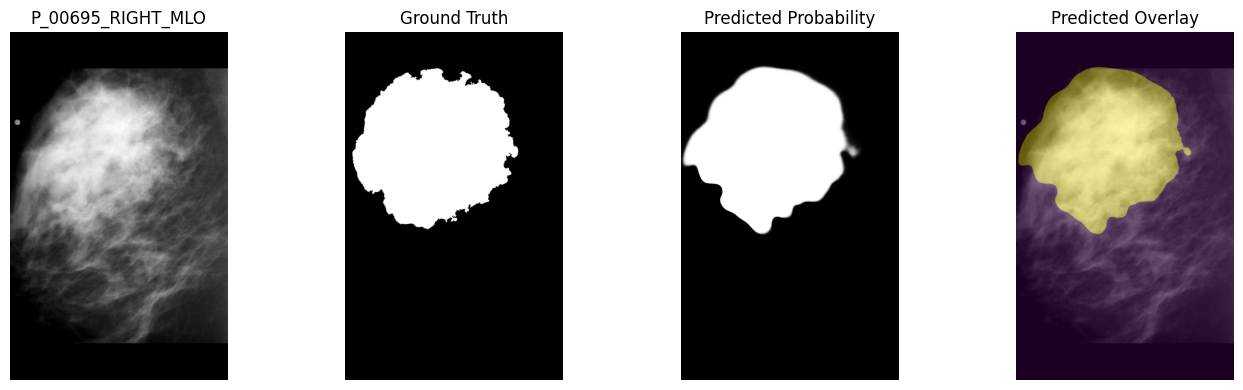

In [127]:
def visualize_predictions(
    model,
    dataset,
    device,
    max_samples=8,
):

    model.eval()

    num_samples = min(
        max_samples,
        len(dataset),
    )


    fig, axes = plt.subplots(
        num_samples,
        4,
        figsize=(
            14,
            4 * num_samples,
        ),
    )


    if num_samples == 1:
        axes = axes[
            np.newaxis,
            :
        ]


    with torch.inference_mode():

        for i in range(
            num_samples
        ):

            (
                image,
                mask,
                image_key,
            ) = dataset[i]


            logits = model(
                image
                .unsqueeze(0)
                .to(device)
            )


            probability = (
                torch.sigmoid(
                    logits
                )
                .squeeze()
                .cpu()
                .numpy()
            )


            prediction = (
                probability
                >= 0.5
            )


            image_np = (
                image
                .squeeze()
                .numpy()
            )

            mask_np = (
                mask
                .squeeze()
                .numpy()
            )


            axes[i, 0].imshow(
                image_np,
                cmap="gray",
            )

            axes[i, 0].set_title(
                image_key
            )


            axes[i, 1].imshow(
                mask_np,
                cmap="gray",
            )

            axes[i, 1].set_title(
                "Ground Truth"
            )


            axes[i, 2].imshow(
                probability,
                cmap="gray",
                vmin=0,
                vmax=1,
            )

            axes[i, 2].set_title(
                "Predicted Probability"
            )


            axes[i, 3].imshow(
                image_np,
                cmap="gray",
            )

            axes[i, 3].imshow(
                prediction,
                alpha=0.4,
            )

            axes[i, 3].set_title(
                "Predicted Overlay"
            )


            for ax in axes[i]:

                ax.axis("off")


    plt.tight_layout()

    plt.savefig(
        FIGURE_DIR
        / "overfit_predictions.png",
        dpi=180,
        bbox_inches="tight",
    )

    plt.show()


visualize_predictions(
    model=model,
    dataset=overfit_dataset,
    device=device,
)

In [128]:
import json
import shutil
from pathlib import Path


SANITY_ARTIFACT_DIR = Path(
    "/kaggle/working/segmentation_sanity_artifact"
)

SANITY_ARTIFACT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

SANITY_FIGURE_DIR = (
    SANITY_ARTIFACT_DIR / "figures"
)

SANITY_FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# ============================================================
# SAVE SUMMARY
# ============================================================

sanity_summary = {
    "experiment": "single_image_segmentation_overfit",
    "status": "PASS",
    "input_resolution": [
        TARGET_HEIGHT,
        TARGET_WIDTH,
    ],
    "architecture": "U-Net",
    "base_channels": 32,
    "samples": 1,
    "best_epoch": int(
        checkpoint["epoch"]
    ),
    "best_dice": float(
        checkpoint["dice"]
    ),
    "best_iou": float(
        checkpoint["iou"]
    ),
    "target_dice": (
        OVERFIT_TARGET_DICE
    ),
}


with open(
    SANITY_ARTIFACT_DIR
    / "sanity_check_summary.json",
    "w",
) as f:

    json.dump(
        sanity_summary,
        f,
        indent=2,
    )


# ============================================================
# COPY HISTORY
# ============================================================

history_path = (
    OUTPUT_DIR
    / "overfit_history.csv"
)

if history_path.exists():

    shutil.copy2(
        history_path,
        SANITY_ARTIFACT_DIR
        / "overfit_history.csv",
    )


# ============================================================
# COPY BEST CHECKPOINT
# ============================================================

if OVERFIT_CHECKPOINT.exists():

    shutil.copy2(
        OVERFIT_CHECKPOINT,
        SANITY_ARTIFACT_DIR
        / "unet_single_image_overfit_best.pth",
    )


# ============================================================
# COPY FIGURES
# ============================================================

for figure_name in [
    "overfit_loss.png",
    "overfit_metrics.png",
    "overfit_predictions.png",
]:

    source = (
        FIGURE_DIR
        / figure_name
    )

    if source.exists():

        shutil.copy2(
            source,
            SANITY_FIGURE_DIR
            / figure_name,
        )


# ============================================================
# ZIP ARTIFACT
# ============================================================

zip_path = shutil.make_archive(
    "/kaggle/working/"
    "segmentation_sanity_artifact",
    "zip",
    SANITY_ARTIFACT_DIR,
)


print(
    json.dumps(
        sanity_summary,
        indent=2,
    )
)

print(
    "\nSaved artifact:"
)

print(zip_path)

{
  "experiment": "single_image_segmentation_overfit",
  "status": "PASS",
  "input_resolution": [
    1024,
    640
  ],
  "architecture": "U-Net",
  "base_channels": 32,
  "samples": 1,
  "best_epoch": 38,
  "best_dice": 0.952583372592926,
  "best_iou": 0.9094600677490234,
  "target_dice": 0.95
}

Saved artifact:
/kaggle/working/segmentation_sanity_artifact.zip
